# S=7 longer-instruction analysis (read-only; uses the saved notebook 23a/23b predictions)

No training and no re-evaluation; a CPU runtime is enough. Results are for the LAST checkpoint.

**Analysed:** S7_k02345 (held-out k=6, which leaves one `<identity>`, and k=7, which leaves none) and S7_k023456
(held-out k=7), for Transformer AR and the causal encoder.

**What it reports:**
1. k=6 accuracy by WHICH slot holds the single `<identity>`.
2. k=6 / k=7 accuracy by number of C tokens and by whether the overall transform occurs in training. Also per-word
   accuracy (full per-word CSV).
3. Failure types: identity copy, wrong legal transform (and how many have the wrong mirror class), non-legal grid,
   invalid output.
4. Whether a wrong prediction equals the word with ONE operation removed (as if that slot were `<identity>`), by
   the removed operation's position.

**Check.** The sampled test set is rebuilt deterministically and verified record-by-record against the saved
predictions.

**Send back `S7_LongerK_Analysis_Review.ipynb`.**


In [1]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: 22a642f07d2f607817f482ebfb33de3065be471a


In [2]:
# --- CONFIGURATION -------------------------------------------------------------------------------------------------
MODE = "full"
SEED = 42
SUBDIR = "S7_support_sweep_20k_v1"          # notebook 23a/23b results
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE else str(REPO_DIR / "results"))
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
import pandas as pd
pd.set_option("display.max_rows", 500); pd.set_option("display.max_columns", 60); pd.set_option("display.width", 250)
from decompositionality import longk_analysis as LA


Mounted at /content/drive


# Longer-instruction analysis of the S=7 sweep (read-only; LAST checkpoint)
Sampled test sets are rebuilt deterministically and checked record-by-record against the saved predictions. Held-out longer k: S7_k02345 → k=6 (one `<identity>` left) and k=7 (no `<identity>`); S7_k023456 → k=7.


### Sources


,condition,model,status
0,S7_k02345,transformer_ar,ok
1,S7_k02345,causal_encoder,ok
2,S7_k023456,transformer_ar,ok
3,S7_k023456,causal_encoder,ok



### 1. k=6 (S7_k02345): exact accuracy by which slot holds the single <identity>


,condition,model,k,I slot,records,correct,exact_acc
0,S7_k02345,transformer_ar,6,1,2821,36,0.012761
1,S7_k02345,transformer_ar,6,2,2833,37,0.013060
2,S7_k02345,transformer_ar,6,3,2859,41,0.014341
3,S7_k02345,transformer_ar,6,4,2868,42,0.014644
4,S7_k02345,transformer_ar,6,5,2917,41,0.014056
5,S7_k02345,transformer_ar,6,6,2852,41,0.014376
6,S7_k02345,transformer_ar,6,7,2850,33,0.011579
7,S7_k02345,causal_encoder,6,1,2821,2353,0.834101
8,S7_k02345,causal_encoder,6,2,2833,2543,0.897635
9,S7_k02345,causal_encoder,6,3,2859,2668,0.933193



### 2a. Accuracy by number of C tokens


... (20 outputs left out)

,condition,model,k,failed,= drop op #1,= drop op #2,= drop op #3,= drop op #4,= drop op #5,= drop op #6,= drop SOME op (union),union / failed,matches >1 drop (ambiguous),= drop op #7
0,S7_k02345,transformer_ar,6,19729,1102,1003,1514,4310,12512,4404,12512,0.634,7881,NaN
1,S7_k02345,transformer_ar,7,19953,0,0,0,0,0,0,0,0.000,0,0.0
2,S7_k02345,causal_encoder,6,1010,0,0,0,0,0,0,0,0.000,0,NaN
3,S7_k02345,causal_encoder,7,10716,23,52,115,128,128,36,128,0.012,128,0.0
4,S7_k023456,transformer_ar,7,12124,232,310,234,435,1271,738,1333,0.110,1012,357.0
5,S7_k023456,causal_encoder,7,0,0,0,0,0,0,0,0,NaN,0,0.0



### 4b. k=6: dropped-one-op matches by <identity> slot


,condition,model,k,I slot,failed,= drop some op
0,S7_k02345,transformer_ar,6,1,2785,1783
1,S7_k02345,transformer_ar,6,2,2796,1775
2,S7_k02345,transformer_ar,6,3,2818,1776
3,S7_k02345,transformer_ar,6,4,2826,1793
4,S7_k02345,transformer_ar,6,5,2876,1809
5,S7_k02345,transformer_ar,6,6,2811,1822
6,S7_k02345,transformer_ar,6,7,2817,1754
7,S7_k02345,causal_encoder,6,1,468,0
8,S7_k02345,causal_encoder,6,2,290,0
9,S7_k02345,causal_encoder,6,3,191,0



### k=6 accuracy by identity slot


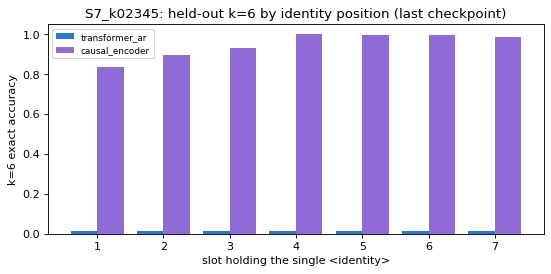


### Per-word accuracy distributions


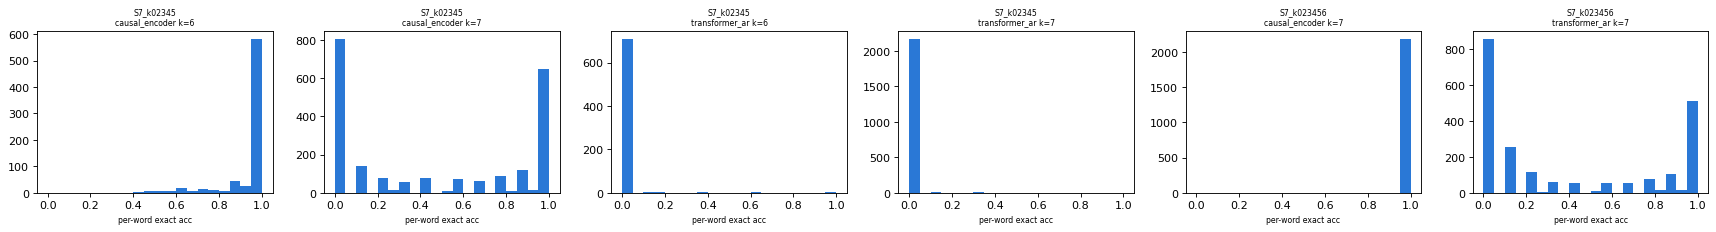

REVIEW FILE: /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1/report/seed_42_longer_k_analysis/S7_LongerK_Analysis_Review.ipynb
REVIEW FILE TO SEND BACK: /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1/report/seed_42_longer_k_analysis/S7_LongerK_Analysis_Review.ipynb


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
# --- Analysis + review export ---------------------------------------------------------------------------------------
rp = LA.analyse(RESULTS_ROOT, MODE, SEED, SUBDIR)
print("REVIEW FILE TO SEND BACK:", rp)
if IN_COLAB:
    from google.colab import files
    files.download(str(rp))
